In [1]:
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle
import collections
import seaborn as sns

**Data loading and processing**

In [2]:
#load data
data = []
with open("/home/nasi4/proj/GWAS/UKBB_201807/results/all.UKBB.hg38.sig.phenotype.bed")as f:
    for line in f:
        data.append(line.strip().split())

In [3]:
#combine label elements
for row in data:
    row.append(' '.join(row[5:]))
    del row[5:-1]

In [4]:
#create dataframe
df = pd.DataFrame(data, columns = ['Chromosome', 'p1', 'p2', 'Reference SNP cluster ID', 'p-value', 'Trait'])

In [5]:
df = df[df['p-value']!='0.00000e+00']
test_list = df['p-value'].to_list()
test_list = list(map(float, test_list))
print(max(test_list))

5e-08


In [6]:
#calculating the negative log of the p-value, setting infinite values to the max non-infinite value observed, and
#normalizing by max -log(p-value) score
pval_mlog = -np.log(list(map(float, list(df['p-value']))))

inf_mask = np.ma.array(pval_mlog, mask=~np.isfinite(pval_mlog))
max_ind = np.ma.argmax(inf_mask, fill_value=-np.inf)
print(max_ind)
max_val = pval_mlog[max_ind]
print(max_val)

for ind in range(len(pval_mlog)):
    if pval_mlog[ind] > pval_mlog[max_ind]:
        pval_mlog[ind] = pval_mlog[max_ind]
        
df['pval_mlog'] = pval_mlog/pval_mlog[max_ind]

736764
743.7469247408213


In [7]:
#creating df with SNP, trait, and p-value
ts_df = df[['Reference SNP cluster ID', 'Trait', 'pval_mlog']]
ts_df.head()

,Reference SNP cluster ID,Trait,pval_mlog
0,rs547522712,Diagnoses - main ICD10: L98 Other disorders of...,0.061532
1,rs547522712,Other disorders of skin and subcutaneous tissu...,0.061532
2,rs547522712,#Spondylopathies,0.058265
3,rs547522712,Diagnoses - main ICD10: M48 Other spondylopathies,0.122894
4,rs547522712,Other and unspecified disorders of skin and su...,0.066955


In [8]:
#finding unique traits and SNPs
SNP_values = np.unique(ts_df['Reference SNP cluster ID'].values)
trait_values = np.unique(ts_df['Trait'].values)

In [9]:
# print(trait_values[0:50])

In [10]:
ts = ts_df.groupby(['Reference SNP cluster ID', 'Trait']).mean()
ts = ts.reset_index()

In [11]:
# print(len(trait_values))
# print(len(SNP_values))

In [12]:
# ts[(ts['Trait']=='3mm strong meridian (right)') & (ts['Reference SNP cluster ID']=='rs570860110')]

In [13]:
# ts[(ts['Trait']=='3mm strong meridian (right)') & (ts['Reference SNP cluster ID']=='rs570860110')]

In [14]:
ts['trait_ind'] = ts.groupby(['Trait']).ngroup()
ts['snp_ind'] = ts.groupby(['Reference SNP cluster ID']).ngroup()

In [15]:
# ts.head(20)

In [16]:
columns = ts['snp_ind'].to_list()
rows = ts['trait_ind'].to_list()
pval_mlog_data = ts['pval_mlog'].to_list()

In [17]:
data_coo = sp.sparse.coo_matrix((pval_mlog_data, (rows, columns)), shape=(len(trait_values), len(SNP_values)))

In [18]:
print(data_coo.max())

1.0


**1st model (k=10 components, epochs=30)**

In [202]:
#splitting data into train and test
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)

In [203]:
data = {'train': train, 'test': test, 'SNP_values' : SNP_values}

In [204]:
#creating model
gwas_model_e30_d10 = LightFM(no_components=10, loss='warp')

In [206]:
#training model
gwas_model_e30_d10.fit(data['train'], epochs=30, num_threads=2)

In [207]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_CT20211004.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

pickle_out_model = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_CT20211004.pickle', 'wb')
pickle.dump(gwas_model_e30_d10, pickle_out_model)
pickle_out_model.close()

In [39]:
pickle_in = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_CT20211004.pickle', 'rb')
gwas_model_e30_d10=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_CT20211004.pickle', 'rb')
data=pickle.load(pickle_in)

In [42]:
test_dense = data['test'].todense()
train_dense = data['train'].todense()

In [41]:
#Calculating precision and recall for test set
test_precision_list_top = []
test_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]: #
    print('k =', k)
    num = []
    n_known_pos = []
    for trait in range(n_traits): 
        if trait % 500 == 0:
            print(trait, '/', n_traits)
        scores = gwas_model_e30_d10.predict(trait, np.arange(n_snps)) 
        top_snps = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, snp_pos in enumerate(np.squeeze(np.asarray(test_dense[trait]))) if snp_pos > 0]
        top_in_known = len([i for i in known_pos if i in top_snps])
        num.append(top_in_known)
        known_pos_len = len(known_pos)
        if (known_pos_len == 0) and (top_in_known == 0):
            known_pos_len = 1
        n_known_pos.append(known_pos_len)
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print('Precision for k=%s : %s' %(k, precision))
    print('Recall for k=%s : %s' %(k, recall))
    test_precision_list_top.append(precision)
    test_recall_list_top.append(recall)

k = 1
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=1 : 0.03669724770642202
Recall for k=1 : 0.00020642155121893197
k = 10
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=10 : 0.0272608125819135
Recall for k=10 : 0.0015304969110941317
k = 100
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=100 : 0.0178348623853211
Recall for k=100 : 0.009815519200025173
k = 1000
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=1000 : 0.013075753604193972
Recall for k=1000 : 0.044267974585764494
k = 10000
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=10000 : 0.009081572739187417
Recall for k=10000 : 0.19320361731253163


In [44]:
#Calculating precision and recall for train set
train_precision_list_top = []
train_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]: #
    print('k =', k)
    num = []
    n_known_pos = []
    for trait in range(n_traits): 
        if trait % 500 == 0:
            print(trait, '/', n_traits)
        scores = gwas_model_e30_d10.predict(trait, np.arange(n_snps)) 
        top_snps = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, snp_pos in enumerate(np.squeeze(np.asarray(train_dense[trait]))) if snp_pos > 0]
        top_in_known = len([i for i in known_pos if i in top_snps])
        num.append(top_in_known)
        known_pos_len = len(known_pos)
        if (known_pos_len == 0) and (top_in_known == 0):
            known_pos_len = 1
        n_known_pos.append(known_pos_len)
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print('Precision for k=%s : %s' %(k, precision))
    print('Recall for k=%s : %s' %(k, recall))
    train_precision_list_top.append(precision)
    train_recall_list_top.append(recall)

k = 1
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=1 : 0.15072083879423329
Recall for k=1 : 0.000585768343423052
k = 10
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=10 : 0.13543905635648756
Recall for k=10 : 0.002526797121104957
k = 100
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=100 : 0.09732634338138925
Recall for k=100 : 0.013288515742045487
k = 1000
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=1000 : 0.07977745740498034
Recall for k=1000 : 0.06320866483635111
k = 10000
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=10000 : 0.05823874180865006
Recall for k=10000 : 0.2916133272199738


In [3]:
test_precision_list_top = [0.03669724770642202, 0.0272608125819135, 0.0178348623853211, 0.013075753604193972, 0.009081572739187417]
test_recall_list_top = [0.00020642155121893197, 0.0015304969110941317, 0.009815519200025173, 0.044267974585764494, 0.19320361731253163]
train_precision_list_top = [0.15072083879423329, 0.13543905635648756, 0.09732634338138925, 0.07977745740498034, 0.05823874180865006]
train_recall_list_top = [0.000585768343423052, 0.002526797121104957, 0.013288515742045487, 0.06320866483635111, 0.2916133272199738]

Text(0.5, 1.0, 'Precision-Recall Curves for GWAS LightFM model (30 epochs, 10 components)')

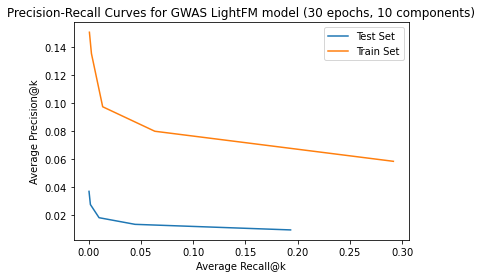

In [4]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
plt.plot(test_recall_list_top, test_precision_list_top)
plt.plot(train_recall_list_top, train_precision_list_top)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for GWAS LightFM model (30 epochs, 10 components)')

**2nd Model (k=10 components, epochs=30, L2 regularization=0.05)** 

In [51]:
#creating model
gwas_model_e30_d10_reg05 = LightFM(no_components=10, loss='warp', item_alpha=0.05, user_alpha=0.05)
#training model
gwas_model_e30_d10_reg05.fit(data['train'], epochs=30, num_threads=2)

In [68]:
user_b, user_e = gwas_model_e30_d10_reg05.get_user_representations()
print(user_e)

[[ 0.  0.  0. ...  0.  0. -0.]
 [-0. -0. -0. ... -0. -0. -0.]
 [-0.  0.  0. ... -0. -0. -0.]
 ...
 [-0.  0. -0. ... -0.  0.  0.]
 [ 0.  0. -0. ...  0.  0. -0.]
 [ 0.  0. -0. ...  0. -0.  0.]]


In [52]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_reg05_CT20211006.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

pickle_out_model = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg05_CT20211006.pickle', 'wb')
pickle.dump(gwas_model_e30_d10_reg05, pickle_out_model)
pickle_out_model.close()

**3rd Model (k=10 components, epochs=30, L2 regularization=0.00001)**

In [65]:
#creating model
gwas_model_e30_d10_reg00001 = LightFM(no_components=10, loss='warp', item_alpha=0.00001, user_alpha=0.00001)
#training model
gwas_model_e30_d10_reg00001.fit(data['train'], epochs=30, num_threads=2)

In [ ]:
user_b, user_e = gwas_model_e30_d10_reg00001.get_user_representations()
print(user_e)
item_b, item_e = gwas_model_e30_d10_reg00001.get_item_representations()
print(item_e)

In [72]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_reg00001_CT20211006.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

pickle_out_model = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg00001_CT20211006.pickle', 'wb')
pickle.dump(gwas_model_e30_d10_reg00001, pickle_out_model)
pickle_out_model.close()

In [19]:
pickle_in = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg00001_CT20211006.pickle', 'rb')
gwas_model_e30_d10_reg00001=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_reg00001_CT20211006.pickle', 'rb')
data_e30_d10_reg00001=pickle.load(pickle_in)

In [27]:
sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['#Arthrosis'])

Disease: #Arthrosis (0)
   Known Positives:
      Reference SNP cluster ID: rs559230165, chr1:219580670-219580671, p-value = 2.51849e-11
      Reference SNP cluster ID: rs1415293, chr1:219556664-219556665, p-value = 3.90813e-11
      Reference SNP cluster ID: rs4846303, chr1:219557457-219557458, p-value = 3.98795e-11
      Reference SNP cluster ID: rs2785998, chr1:219561656-219561657, p-value = 4.22478e-11
      Reference SNP cluster ID: rs1337101, chr1:219552758-219552759, p-value = 4.29033e-11
      ...

   Recommended:
      Reference SNP cluster ID: rs6088812, chr20:35386360-35386361
      Reference SNP cluster ID: rs3751812, chr16:53784548-53784549
      Reference SNP cluster ID: rs142570322, chr20:35415270-35415271
      Reference SNP cluster ID: rs6088823, chr20:35406462-35406463
      Reference SNP cluster ID: 20:34008020_CTTTTT_C, chr20:35420217-35420218



In [20]:
# list(df[(df['Reference SNP cluster ID']=='rs142570322')]['Trait'])

In [74]:
#Precision and Recall @ k scores for GWAS_model_e30_d10_reg00001
with open('GWAS_model_e30_d10_reg00001_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
print()
with open('GWAS_model_e30_d10_reg00001_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.047706422018348627, 0.03570117955439057, 0.02088597640891219, 0.014419134993446922, 0.009612686762778504] \n', 'Test Recall@[1, 10, 100, 1000, 10000] = [0.0002961707086960372, 0.0020029763996970615, 0.011315624697549159, 0.051558639864080824, 0.20673388679643967]']

['Train Precision@[1, 10, 100, 1000, 10000] = [0.1931847968545216, 0.17197903014416774, 0.1127732634338139, 0.08671638269986894, 0.06017397116644824] \n', 'Train Recall@[1, 10, 100, 1000, 10000] = [0.0008907617239523477, 0.002966070034065296, 0.015061163811320196, 0.06995856147627036, 0.2891865702674004]']


In [5]:
test_precision_e30_d10_reg00001 = [0.047706422018348627, 0.03570117955439057, 0.02088597640891219, 0.014419134993446922, 0.009612686762778504]
test_recall_e30_d10_reg00001 = [0.0002961707086960372, 0.0020029763996970615, 0.011315624697549159, 0.051558639864080824, 0.20673388679643967]

train_precision_e30_d10_reg00001 = [0.1931847968545216, 0.17197903014416774, 0.1127732634338139, 0.08671638269986894, 0.06017397116644824]
train_recall_e30_d10_reg00001 = [0.0008907617239523477, 0.002966070034065296, 0.015061163811320196, 0.06995856147627036, 0.2891865702674004]


Text(0.5, 1.0, 'Precision-Recall Curves for GWAS LightFM model (30 epochs, 10 components, a=0.00001)')

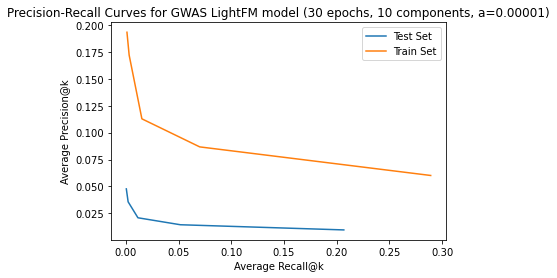

In [6]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
plt.plot(test_recall_e30_d10_reg00001, test_precision_e30_d10_reg00001)
plt.plot(train_recall_e30_d10_reg00001, train_precision_e30_d10_reg00001)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for GWAS LightFM model (30 epochs, 10 components, a=0.00001)')

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (30 epochs, 10 components)')

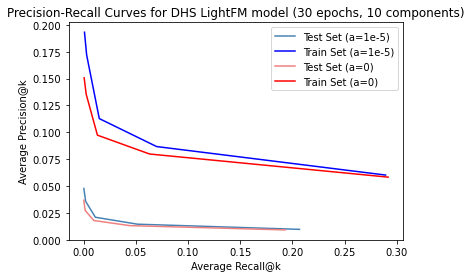

In [34]:
#Plot precision-recall curves for train and test data (30 epochs, 10 dimensions)
plt.plot(test_recall_e30_d10_reg00001, test_precision_e30_d10_reg00001, color='steelblue')
plt.plot(train_recall_e30_d10_reg00001, train_precision_e30_d10_reg00001, color='blue')
plt.plot(test_recall_list_top, test_precision_list_top, color='lightcoral')
plt.plot(train_recall_list_top, train_precision_list_top, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set (a=1e-5)', 'Train Set (a=1e-5)', 'Test Set (a=0)', 'Train Set (a=0)'], 
           loc='upper right')
plt.title('Precision-Recall Curves for DHS LightFM model (30 epochs, 10 components)')
# plt.savefig('PR_Curves_GWAS_model_e30_d10_LightFM_CT20211005.jpeg')

In [53]:
#Calculating precision and recall for test set
#DELETE THIS CELL
test_precision_list_top_del = []
test_recall_list_top_del = []
test_dense = data['test'].todense()
for k in [1, 10, 100, 1000, 10000]: #
    print('k =', k)
    num = []
    n_known_pos = []
    for trait in range(n_traits): 
        if trait % 500 == 0:
            print(trait, '/', n_traits)
        scores = gwas_model_e30_d10_reg05.predict(trait, np.arange(n_snps)) 
        top_snps = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, snp_pos in enumerate(np.squeeze(np.asarray(test_dense[trait]))) if snp_pos > 0]
        top_in_known = len([i for i in known_pos if i in top_snps])
        num.append(top_in_known)
        known_pos_len = len(known_pos)
        if (known_pos_len == 0) and (top_in_known == 0):
            known_pos_len = 1
        n_known_pos.append(known_pos_len)
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print('Precision for k=%s : %s' %(k, precision))
    print('Recall for k=%s : %s' %(k, recall))
    test_precision_list_top_del.append(precision)
    test_recall_list_top_del.append(recall)

k = 1
0 / 3815
500 / 3815
1000 / 3815
1500 / 3815
2000 / 3815
2500 / 3815
3000 / 3815
3500 / 3815
Precision for k=1 : 0.0
Recall for k=1 : 0.0
k = 10
0 / 3815


KeyboardInterrupt: 

**Function to recommend SNPs given a trait**

In [55]:
full_data = data_coo
trait = 'Impedance of leg (left)'
ts[ts['Trait']==trait]
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]

known_ranked = list(np.squeeze(np.asarray(np.argsort(-data_coo.todense()[trait_ind, :]))))
# print(known_ranked[0])
n_traits, n_snps = data['train'].shape
scores = gwas_model.predict(trait_ind, np.arange(n_snps))
top_SNPs = np.argsort(-scores)
# print(top_SNPs[2090232])

1431229
1049063


In [20]:
#number of diseases and genes in training dataset
n_traits, n_snps = data_e30_d10_reg00001['train'].shape
print(n_traits, n_snps)

3815 2090230


In [21]:
# x = ts[(ts['Trait']=='#Arthrosis')].sort_values('pval_mlog', ascending=False)
# # x
# s = ts[ts['snp_ind'] == 1417868]['Reference SNP cluster ID'].tolist()[0]

# list(df.index[(df['Reference SNP cluster ID']==s) & (df['Trait']=='#Arthrosis')])[0]

# # df[(df['Trait']=='#Arthrosis')]['p1']
# df_reset = df.reset_index()
# # df_reset
# chrom_list = df_reset['Chromosome']
# # chrom_list
# df_reset[(df_reset['Reference SNP cluster ID']==s)]


In [41]:
#function to recommend SNPs for a given trait. Takes in the model, data, and a list of
#traits for SNPs to be recommend for. For each trait, prints out known associated SNPs
#and a list of recommended genes. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(model, data, traits, print_num=5, recommend_num=5, full_data=data_coo):
    
    
    #generate gene recommendations for each disease
    return_list = []
    for trait in traits:
        trait_list = []
        trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
        #genes known to relate to the disease
#         known_ranked = list(np.squeeze(np.asarray(np.argsort(-data_coo.todense()[trait_ind, :]))))
        known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
        known_ranked = list(known_ranked_df['snp_ind'])
        
#         print((known_ranked[1]))
        not_known_ind = list(set(np.arange(n_snps)) - set(known_ranked))
#         print(type(not_known_ind[3]))
        nki_series = pd.Series(not_known_ind)
    
        #genes model predicts that relate to disease
#         scores = model.predict(trait_ind, np.arange(n_snps))
        filtered_scores = model.predict(trait_ind, np.array(not_known_ind))
        #rank from most related to least
        filtered_top_snps = [np.argsort(-filtered_scores)][0]
        top_SNPs = nki_series[filtered_top_snps]
#         print(filtered_top_snps[0])
#         print(top_SNPs[0:3])
#         top_SNPs = np.argsort(-scores)
        
        #print results
        print('Disease: ' + trait + ' (' + str(trait_ind) +')')
        print('   Known Positives:')
        
#         known_pos = [] 
#         known_pval_mlog = []
#         ts_dense = full_data.todense()
#         known_pos = ts[(ts['Trait']==trait)]['Reference SNP cluster ID'].to_list()
        
        df_reset = df.reset_index()
        chrom_list = df_reset['Chromosome']
        p1_list = df_reset['p1']
        p2_list = df_reset['p2']
        pval_list = df_reset['p-value']
    
        for snp in known_ranked[:5]:
#             pval_mlog = ts_dense[trait_ind, snp]*max_val
#             pval_mlog = list(known_ranked_df[known_ranked_df['snp_ind']==snp]['pval_mlog'])[0]*max_val
#             if pval_mlog == 0:
#                 break
            s = ts[ts['snp_ind'] == snp]['Reference SNP cluster ID'].tolist()[0]
            s_ind = list(df_reset.index[(df_reset['Reference SNP cluster ID']==s) & (df_reset['Trait']==trait)])[0]
            chrom = chrom_list[s_ind]
            p1 = p1_list[s_ind]
            p2 = p2_list[s_ind]
            pval = pval_list[s_ind]
#             chrom = df[df['Reference SNP cluster ID']==s]['Chromosome'].to_list()[0]
#             p1 = df[df['Reference SNP cluster ID']==s]['p1'].to_list()[0]
#             p2 = df[df['Reference SNP cluster ID']==s]['p2'].to_list()[0]
#             pval = df[(df['Reference SNP cluster ID']==s) & (df['Trait']==trait)]['p-value'].to_list()[0]
            print('      Reference SNP cluster ID: %s, %s:%s-%s, p-value = %s' %(s, chrom, p1, p2, pval))
        print('      ...')
        
        print()
        print('   Recommended:')
        count = 0
        rec_s = []
        rec_chrom = []
        rec_p1 = []
        rec_p2 = []
        for snp in top_SNPs[:]:
            s = ts[ts['snp_ind'] == snp]['Reference SNP cluster ID'].tolist()[0]
#             print(s)
            s_ind = list(df_reset.index[(df_reset['Reference SNP cluster ID']==s)])[0]
            chrom = chrom_list[s_ind]
            p1 = p1_list[s_ind]
            p2 = p2_list[s_ind]
            rec_s.append(s)
            rec_chrom.append(chrom)
            rec_p1.append(p1)
            rec_p2.append(p2)
#             if s not in known_pos:
#             chrom = df[df['Reference SNP cluster ID']==s]['Chromosome'].to_list()[0]
#             p1 = df[df['Reference SNP cluster ID']==s]['p1'].to_list()[0]
#             p2 = df[df['Reference SNP cluster ID']==s]['p2'].to_list()[0]
            
            if count < print_num:
                print('      Reference SNP cluster ID: %s, %s:%s-%s' %(s, chrom, p1, p2))
            count += 1
            if count == recommend_num:
                trait_list.append(rec_s)
                trait_list.append(rec_chrom)
                trait_list.append(rec_p1)
                trait_list.append(rec_p2)
                break
                
            return_list.append(trait_list)
        return return_list
            
rec_info = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['#Arthrosis'], recommend_num=10)

Disease: #Arthrosis (0)
   Known Positives:
      Reference SNP cluster ID: rs559230165, chr1:219580670-219580671, p-value = 2.51849e-11
      Reference SNP cluster ID: rs1415293, chr1:219556664-219556665, p-value = 3.90813e-11
      Reference SNP cluster ID: rs4846303, chr1:219557457-219557458, p-value = 3.98795e-11
      Reference SNP cluster ID: rs2785998, chr1:219561656-219561657, p-value = 4.22478e-11
      Reference SNP cluster ID: rs1337101, chr1:219552758-219552759, p-value = 4.29033e-11
      ...

   Recommended:
      Reference SNP cluster ID: rs6088812, chr20:35386360-35386361
      Reference SNP cluster ID: rs3751812, chr16:53784548-53784549
      Reference SNP cluster ID: rs142570322, chr20:35415270-35415271
      Reference SNP cluster ID: rs6088823, chr20:35406462-35406463
      Reference SNP cluster ID: 20:34008020_CTTTTT_C, chr20:35420217-35420218


In [42]:
# #expected output

# Disease: #Arthrosis (0)
#    Known Positives:
#       Reference SNP cluster ID: rs559230165, chr1:219580670-219580671, p-value = 2.51849e-11
#       Reference SNP cluster ID: rs1415293, chr1:219556664-219556665, p-value = 3.90813e-11
#       Reference SNP cluster ID: rs4846303, chr1:219557457-219557458, p-value = 3.98795e-11
#       Reference SNP cluster ID: rs2785998, chr1:219561656-219561657, p-value = 4.22478e-11
#       Reference SNP cluster ID: rs1337101, chr1:219552758-219552759, p-value = 4.29033e-11
#       ...

#    Recommended:
#       Reference SNP cluster ID: rs6088812, chr20:35386360-35386361
#       Reference SNP cluster ID: rs3751812, chr16:53784548-53784549
#       Reference SNP cluster ID: rs142570322, chr20:35415270-35415271
#       Reference SNP cluster ID: rs6088823, chr20:35406462-35406463
#       Reference SNP cluster ID: 20:34008020_CTTTTT_C, chr20:35420217-35420218

In [43]:
# list(df[df['Reference SNP cluster ID']=='rs6088812']['Trait'])

In [44]:
def rec_snp_traits(snp_list):
    total_traits = []
    snp_traits_list = []
    for snp in snp_list:
        snp_traits = np.unique(list(df[df['Reference SNP cluster ID']==snp]['Trait']))
        snp_traits_list.append(snp_traits)
        total_traits.extend(snp_traits)
    trait_counter = collections.Counter(total_traits)
    zipped_traits_counts = zip(list(trait_counter.values()), list(trait_counter.keys()))
    sorted_zipped = sorted(zipped_traits_counts, reverse=True)
    zipped_ordered = zip(*sorted_zipped)
    counts, traits = [ list(tuple) for tuple in  zipped_ordered]
    m = np.zeros((len(snp_list), len(traits)))
    for i in range(len(snp_list)):
        for element in snp_traits_list[i]:
            ind = traits.index(element)
            m[i, ind] = 1
    return m, traits
    
m, traits = rec_snp_traits(rec_info[0][0])

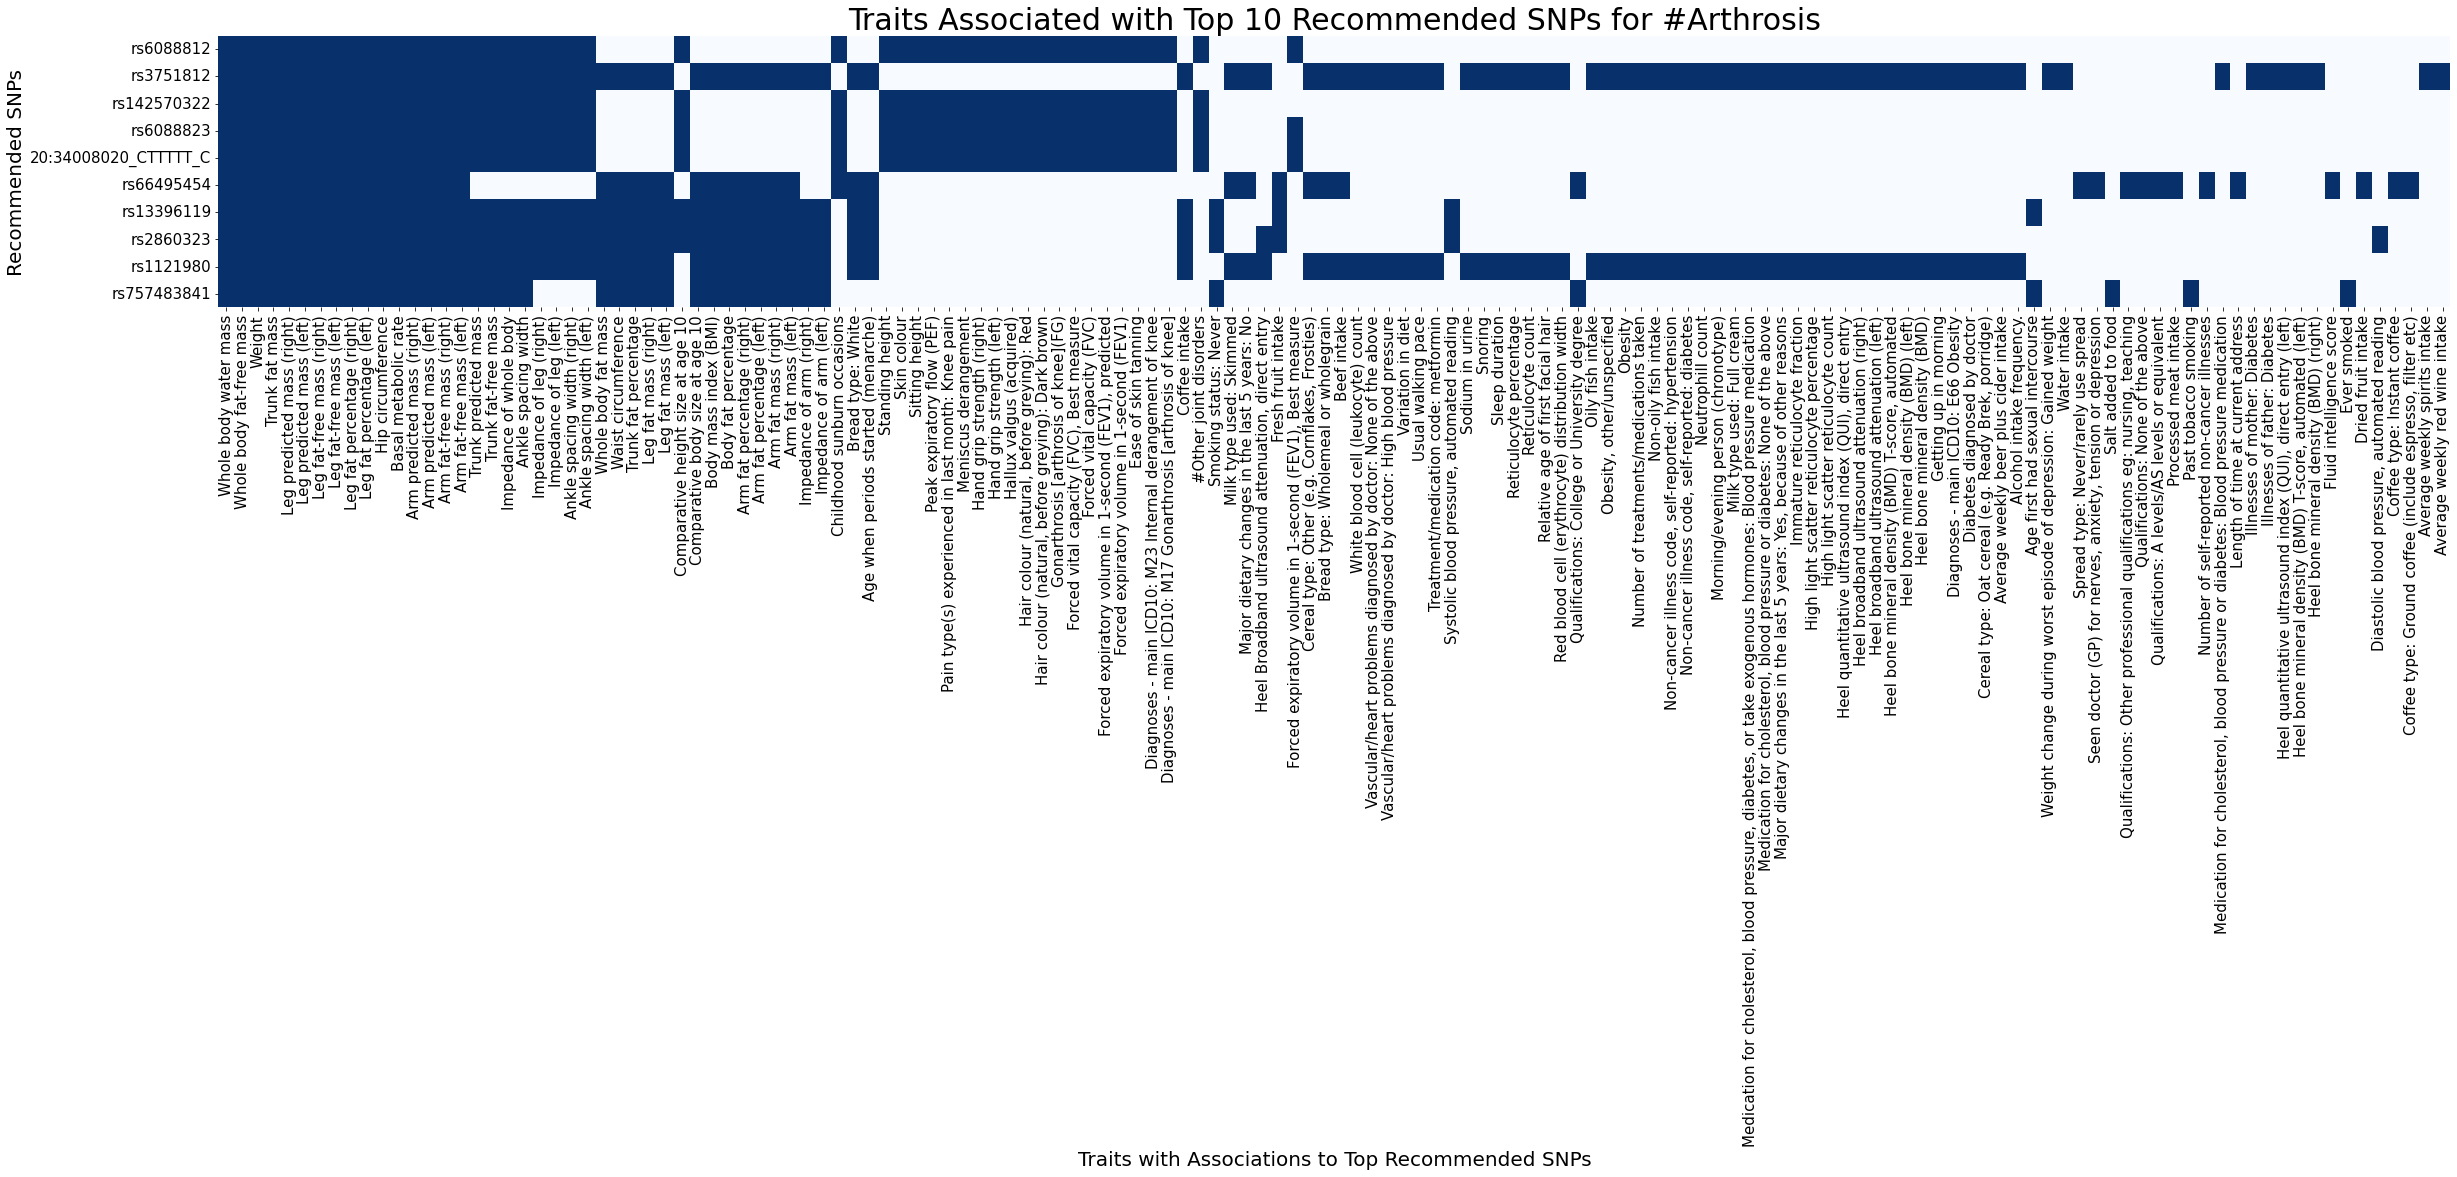

In [47]:
# plt.imshow(m, cmap=plt.cm.Greys, interpolation='nearest', aspect='auto')
plt.subplots(figsize=(40,5))
ax = sns.heatmap(m, yticklabels=rec_info[0][0], xticklabels=traits, cmap='Blues', cbar=False)
ax.set_title('Traits Associated with Top 10 Recommended SNPs for #Arthrosis', fontsize=30)
ax.set_ylabel('Recommended SNPs', fontsize=20)
ax.set_xlabel('Traits with Associations to Top Recommended SNPs', fontsize=20)
ax.tick_params(labelsize=15)
# ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
# print(traits[:5])

In [ ]:
def check_full_data():
    return

In [ ]:
#AUC score
auc_score = auc_score(gwas_model_e30_d10, data['test'])

In [ ]:
n_traits, n_snp = data['train'].shape
scores = model.predict(15, np.arange(n_SNPs))
top_genes = data['gene_ids'][np.argsort(-scores)]

In [19]:
df[(df['Reference SNP cluster ID']=='rs570860110')&(df['Trait']=='3mm strong meridian (right)')]

,Chromosome,p1,p2,Reference SNP cluster ID,p-value,Trait,pval_mlog
1009286,chr1,202817700,202817701,rs570860110,1.63190e-11,3mm strong meridian (right),0.033397
1009292,chr1,202817700,202817701,rs570860110,3.26722e-11,3mm strong meridian (right),0.032463
1009300,chr1,202817700,202817701,rs570860110,4.72082e-12,3mm strong meridian (right),0.035064
1009308,chr1,202817700,202817701,rs570860110,9.41552e-12,3mm strong meridian (right),0.034136


In [99]:
# counter = 0
# for trait in trait_values:
# #     print(trait)
#     trait_df = ts_df[ts_df['Trait']==trait].set_index('Reference SNP cluster ID')
#     duplicate_list = np.unique(list(trait_df[trait_df.index.duplicated()].index))
#     if len(duplicate_list) > 0:
#         entry_list = np.array([])
#         for duplicate in duplicate_list:
# #             print(duplicate)
#             ave = np.mean(trait_df.loc[duplicate]['pval_mlog'])
#             trait_df = trait_df.drop(duplicate)
#             np.append(entry_list, [trait, ave, duplicate], axis=0)
#         entry = pd.DataFrame(list(entry_list), columns=['Trait', 'pval_mlog', 'Reference SNP cluster ID'])
#         entry = entry.set_index('Reference SNP cluster ID')
# #         print('entry done')
#         trait_df = trait_df.append(entry)
# #         print('df done')
#     ts_matrix.loc[trait] = trait_df['pval_mlog']
# #     print('main df done')
#     if counter%50 == 0:
#         print('Trait %s done' %(counter))
#     counter+=1

# ts_np = ts_matrix.to_numpy()
# ts_np = np.array(ts_np, dtype=float)
# ts_np[np.isnan(ts_np)] = 0
# ts_coo = sp.sparse.coo_matrix(ts_np)
# print(ts_coo)

In [45]:
# ts[(ts['Reference SNP cluster ID']=='rs4502182')]

In [46]:
# ts[(ts['Reference SNP cluster ID']=='rs13003430')]